# Notebook 15 — Cross-Source Evaluation 



## Step 1 — Setup and Configuration

In [1]:
import os, re, json, time, random, itertools, warnings
import numpy as np, pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score
warnings.filterwarnings("ignore")

GLOBAL_SEED   = 42
DETERMINISTIC = False          # True = bit-reproducible but ~2x slower (cudnn.deterministic, no AMP)
def set_seed(s=GLOBAL_SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def seed_worker(_):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = DETERMINISTIC
torch.backends.cudnn.benchmark     = not DETERMINISTIC
USE_AMP = device.type == "cuda" and not DETERMINISTIC
print(f"Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "") + f" | AMP: {USE_AMP}")

DATASET_ROOT = "/home/ali/Desktop/Algerian_Lamiaceae_v3"
SPLIT_DIRS   = ["train", "val", "test"]
OUTPUT_DIR   = os.path.join(DATASET_ROOT, "results", "cross_source_v2")
V1_DIR       = os.path.join(DATASET_ROOT, "results", "cross_source")
RUNS_DIR     = os.path.join(OUTPUT_DIR, "runs")                         # one JSON per finished run (resume)
NOBG_DIR     = Path(DATASET_ROOT) / "results" / "nobg_cache"           # full-size rembg output (reused)
SMALL_DIR    = Path(DATASET_ROOT) / "results" / "img_cache_320"        # resized cache used for training
os.makedirs(RUNS_DIR, exist_ok=True)
METADATA_CSV = os.path.join(DATASET_ROOT, "metadata_cleaned.csv")
assert os.path.exists(METADATA_CSV), f"{METADATA_CSV} not found -- run prep notebook Step 14b first"

MIN_PER_CLASS_PER_SOURCE = 20
VAL_FRAC, TEST_FRAC = 0.15, 0.15
IMG_EXT    = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SHORT_SIDE = 320               # cached short side (> 256 used by Resize/RandomResizedCrop)

BATCH_SIZE   = 32 if device.type == "cuda" else 16
NUM_WORKERS  = min(8, os.cpu_count() or 4)
LR_P1, LR_P2 = 1e-3, 1e-5
EPOCHS_P1, EPOCHS_P2     = 15, 15
PATIENCE_P1, PATIENCE_P2 = 7, 5
LABEL_SMOOTHING, GRAD_CLIP_NORM = 0.1, 1.0
CKPT_METRIC  = "macro_f1"
N_BOOT       = 1000
BG_FILL_RGB, MIN_FG_FRACTION = (124, 116, 104), 0.03
MIN_SANITY_BAL_ACC = 80.0
RUN_EXPERIMENT_A, RUN_EXPERIMENT_B, RUN_EXPERIMENT_C = True, True, True

CONFIG = dict(EPOCHS_P1=EPOCHS_P1, EPOCHS_P2=EPOCHS_P2, BATCH_SIZE=BATCH_SIZE, LR_P1=LR_P1, LR_P2=LR_P2,
              SHORT_SIDE=SHORT_SIDE, USE_AMP=USE_AMP, DETERMINISTIC=DETERMINISTIC, FIX_EVAL_TRANSFORM=True,
              FREEZE_BN_STATS=True, REMOVE_BACKGROUND=True, STRONG_AUG=True, SOURCE_BALANCED=True)
print(json.dumps(CONFIG))

Device: cuda (NVIDIA GeForce RTX 4070 Laptop GPU) | AMP: True
{"EPOCHS_P1": 15, "EPOCHS_P2": 15, "BATCH_SIZE": 32, "LR_P1": 0.001, "LR_P2": 1e-05, "SHORT_SIDE": 320, "USE_AMP": true, "DETERMINISTIC": false, "FIX_EVAL_TRANSFORM": true, "FREEZE_BN_STATS": true, "REMOVE_BACKGROUND": true, "STRONG_AUG": true, "SOURCE_BALANCED": true}


## Step 2 — Image Manifest with Source, Class × Source Table, Species within Class

In [2]:
meta = pd.read_csv(METADATA_CSV, encoding="utf-8-sig")
meta["key_split"] = meta.dest_path.map(lambda p: Path(str(p)).parent.parent.name)
meta["key_cls"]   = meta.dest_path.map(lambda p: Path(str(p)).parent.name)
meta["key_name"]  = meta.dest_path.map(lambda p: Path(str(p)).name)
recs = meta.to_dict("records")
by_full  = {(r["key_split"], r["key_cls"], r["key_name"]): r for r in recs}
sn_cnt   = meta.groupby(["key_split", "key_name"]).size()
by_split = {(r["key_split"], r["key_name"]): r for r in recs if sn_cnt[(r["key_split"], r["key_name"])] == 1}
nm_cnt   = meta.key_name.value_counts()
by_name  = {r["key_name"]: r for r in recs if nm_cnt[r["key_name"]] == 1}

rows = []
for sp in SPLIT_DIRS:                                   # originals only (augmented copies are not used)
    sp_dir = Path(DATASET_ROOT) / sp
    if not sp_dir.exists(): continue
    for cls_dir in sorted(p for p in sp_dir.iterdir() if p.is_dir()):
        for f in cls_dir.iterdir():
            if f.suffix.lower() not in IMG_EXT or f.name.startswith("aug_"): continue
            r = by_full.get((sp, cls_dir.name, f.name)) or by_split.get((sp, f.name)) or by_name.get(f.name)
            rows.append({"path": str(f), "cls": cls_dir.name, "orig_split": sp,
                         "source": r["source"] if r else "UNKNOWN",
                         "species_original": (r.get("original_name") if isinstance(r.get("original_name"), str) else r["species"]) if r else "UNKNOWN",
                         "src_folder": Path(str(r["src_path"])).parent.name if r else "UNKNOWN"})
manifest = pd.DataFrame(rows)
print(f"Originals on disk: {len(manifest):,} | unresolved source: {(manifest.source == 'UNKNOWN').sum()}")
manifest.to_csv(os.path.join(OUTPUT_DIR, "image_manifest_with_source.csv"), index=False)
data = manifest[manifest.source != "UNKNOWN"].reset_index(drop=True)

ct = pd.crosstab(data.cls, data.source, margins=True)
print(f"\nOriginal images used: {len(data):,}\n\nCLASS x SOURCE table:\n{ct.to_string()}")
ct.to_csv(os.path.join(OUTPUT_DIR, "class_by_source_table.csv"))
data.groupby(["cls", "source", "species_original", "src_folder"]).size().rename("n_images").reset_index() \
    .to_csv(os.path.join(OUTPUT_DIR, "species_within_class_by_source.csv"), index=False)

counts_cs = pd.crosstab(data.cls, data.source)
sources   = counts_cs.columns.tolist()
multi_src_classes = counts_cs.index[(counts_cs >= MIN_PER_CLASS_PER_SOURCE).sum(1) >= 2].tolist()
all_classes = sorted(data.cls.unique())
print(f"\nClasses with >= {MIN_PER_CLASS_PER_SOURCE} originals in >= 2 sources: {multi_src_classes}")

Originals on disk: 15,881 | unresolved source: 0

Original images used: 15,881

CLASS x SOURCE table:
source                  MedLeaves  Medicinal Leaf Dataset  PlantNet-300K    All
cls                                                                            
Lamium_pooled                   0                       0           8063   8063
Lavandula_angustifolia          0                       0           3399   3399
Lavandula_pooled                0                       0           3373   3373
Leucas_aspera                   0                      74              0     74
Mentha_pooled                 195                     127              0    322
Ocimum_pooled                 344                       0              0    344
Plectranthus_pooled           182                     124              0    306
All                           721                     325          14835  15881

Classes with >= 20 originals in >= 2 sources: ['Mentha_pooled', 'Plectranthus_pooled']


## Step 2b — Background Removal + Resized Cache (run once)

rembg is only called for images missing from `nobg_cache` (the previous run already produced all of them). Both the background-removed and the original images are then resized once to a 320-px short side; JPEG draft mode makes the decoding fast.

In [3]:
def nobg_path(p):  p = Path(p); return NOBG_DIR / p.parent.parent.name / p.parent.name / (p.stem + ".jpg")
def small_path(p, kind): p = Path(p); return SMALL_DIR / kind / p.parent.parent.name / p.parent.name / (p.stem + ".jpg")

missing = [p for p in data.path if not nobg_path(p).exists()]
if missing:                                            # rembg only for images not processed before
    from rembg import remove, new_session              # pip install "rembg[gpu]"  (or rembg[cpu])
    session = new_session("u2net"); t0 = time.time()
    for i, p in enumerate(missing, 1):
        img = Image.open(p).convert("RGB"); rgba = remove(img, session=session)
        fg = float((np.asarray(rgba.split()[-1]) > 127).mean())
        out = nobg_path(p); out.parent.mkdir(parents=True, exist_ok=True)
        if fg < MIN_FG_FRACTION: img.save(out, quality=95)
        else:
            bg = Image.new("RGB", img.size, BG_FILL_RGB); bg.paste(rgba.convert("RGB"), mask=rgba.split()[-1]); bg.save(out, quality=95)
        if i % 500 == 0 or i == len(missing): print(f"  rembg {i:,}/{len(missing):,} ({time.time()-t0:.0f}s)")
print(f"Background-removed images available: {len(data) - len(missing):,} cached + {len(missing):,} new")

def make_small(src, dst):
    if dst.exists(): return
    dst.parent.mkdir(parents=True, exist_ok=True)
    im = Image.open(src); im.draft("RGB", (SHORT_SIDE * 2, SHORT_SIDE * 2))   # fast JPEG decode at reduced scale
    im = im.convert("RGB"); s = SHORT_SIDE / min(im.size)
    if s < 1: im = im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR)
    im.save(dst, quality=95)

t0 = time.time(); jobs = []
for p in data.path:
    jobs += [(nobg_path(p), small_path(p, "nobg")), (Path(p), small_path(p, "orig"))]
todo = [j for j in jobs if not j[1].exists()]
with ThreadPoolExecutor(NUM_WORKERS) as ex:
    for i, _ in enumerate(ex.map(lambda j: make_small(*j), todo), 1):
        if i % 2000 == 0: print(f"  resized {i:,}/{len(todo):,} ({time.time()-t0:.0f}s)")
print(f"Resized cache ready: {len(todo):,} new files, {len(jobs) - len(todo):,} already cached ({time.time()-t0:.0f}s)")
data["path_original"] = [str(small_path(p, "orig")) for p in data.path]
data["path"]          = [str(small_path(p, "nobg")) for p in data.path]

Background-removed images available: 15,881 cached + 0 new
Resized cache ready: 0 new files, 31,762 already cached (1s)


## Step 3 — Training / Evaluation Utilities (NB14 recipe + v2 fixes)

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.4, 1.0), ratio=(0.75, 1.33)),
                      T.RandomHorizontalFlip(), T.RandomVerticalFlip(p=0.5), T.RandomRotation(30),
                      T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.05), T.RandomGrayscale(p=0.1),
                      T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
                      T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.25, scale=(0.02, 0.15))])
eval_tf  = T.Compose([T.Resize((256, 256)), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

class ListDataset(Dataset):
    def __init__(self, paths, y, tf): self.paths, self.y, self.tf = list(paths), list(y), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.tf(Image.open(self.paths[i]).convert("RGB")), self.y[i]

def make_loader(df, c2i, train, col="path"):
    ds = ListDataset(df[col], df.cls.map(c2i), train_tf if train else eval_tf)
    g = torch.Generator(); g.manual_seed(GLOBAL_SEED)
    kw = dict(batch_size=BATCH_SIZE if train else 128, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
              worker_init_fn=seed_worker, generator=g, persistent_workers=train and NUM_WORKERS > 0,
              prefetch_factor=4 if NUM_WORKERS > 0 else None)
    if not train: return DataLoader(ds, shuffle=False, **kw)
    w = 1.0 / (df.groupby(["cls", "source"]).path.transform("size") * df.groupby("cls").source.transform("nunique"))
    return DataLoader(ds, sampler=WeightedRandomSampler(torch.DoubleTensor(w.values), len(ds), replacement=True, generator=g), **kw)

def freeze_bn_stats(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()

@torch.no_grad()
def predict(model, loader, proba=False):
    model.eval(); P, Y = [], []
    for x, y in loader:
        with torch.autocast("cuda", enabled=USE_AMP):
            out = model(x.to(device, non_blocking=True).to(memory_format=torch.channels_last))
        P.append((out.float().softmax(1) if proba else out.argmax(1)).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(Y), np.concatenate(P)

def score(y, p, labels):
    return {"accuracy": accuracy_score(y, p) * 100, "balanced_acc": balanced_accuracy_score(y, p) * 100,
            "macro_f1": f1_score(y, p, labels=labels, average="macro", zero_division=0) * 100}

def boot_ci(y, p, K, n=N_BOOT, seed=GLOBAL_SEED):
    """Vectorised percentile bootstrap of macro-F1 over all K labels (identical to sklearn, ~1000x faster)."""
    idx = np.random.RandomState(seed).randint(0, len(y), (n, len(y)))
    codes = (y[idx] * K + p[idx]) + (np.arange(n) * K * K)[:, None]
    cm = np.bincount(codes.ravel(), minlength=n * K * K).reshape(n, K, K)
    tp = np.einsum("bii->bi", cm); den = 2 * tp + (cm.sum(1) - tp) + (cm.sum(2) - tp)
    f1 = 100 * np.divide(2 * tp, den, out=np.zeros(den.shape), where=den > 0).mean(1)
    return float(np.percentile(f1, 2.5)), float(np.percentile(f1, 97.5))

def wilson_ci(k, n, z=1.96):
    if n == 0: return (float("nan"), float("nan"))
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (100 * max(0, c - h), 100 * min(1, c + h))

def train_model(train_df, val_df, classes, tag):
    """Two-phase EfficientNet-B3 (NB14 recipe), BN statistics frozen, checkpoint on validation macro-F1."""
    set_seed(); t_run = time.time()
    c2i = {c: i for i, c in enumerate(classes)}; labels = list(range(len(classes)))
    tr_loader, vl_loader = make_loader(train_df, c2i, True), make_loader(val_df, c2i, False)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    model = timm.create_model("efficientnet_b3", pretrained=True, num_classes=len(classes)).to(device)
    model = model.to(memory_format=torch.channels_last)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best = {"score": -1, "state": None}

    def run_phase(name, lr, epochs, patience, factor, sched_pat):
        opt = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
        sch = ReduceLROnPlateau(opt, mode="max", factor=factor, patience=sched_pat); wait = 0
        for ep in range(1, epochs + 1):
            model.train(); freeze_bn_stats(model); t0, tot, corr, n = time.time(), 0.0, 0, 0
            for x, y in tr_loader:
                x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(device, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                with torch.autocast("cuda", enabled=USE_AMP):
                    out = model(x); loss = criterion(out, y)
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM); scaler.step(opt); scaler.update()
                tot += loss.item() * len(y); corr += (out.argmax(1) == y).sum().item(); n += len(y)
            vs = score(*predict(model, vl_loader), labels); sch.step(vs[CKPT_METRIC]); mark = ""
            if vs[CKPT_METRIC] > best["score"]:
                best.update(score=vs[CKPT_METRIC], state={k: v.detach().clone() for k, v in model.state_dict().items()})
                wait, mark = 0, " <- best"
            else: wait += 1
            print(f"    [{tag}] {name} ep {ep:2d}/{epochs} loss={tot/n:.4f} tr_acc={corr/n*100:5.1f}% "
                  f"val_acc={vs['accuracy']:5.1f}% val_F1={vs['macro_f1']:5.1f}% ({time.time()-t0:.0f}s){mark}", flush=True)
            if wait >= patience: print(f"    [{tag}] {name} early stop at epoch {ep}"); break

    for nm, p in model.named_parameters(): p.requires_grad = "classifier" in nm
    run_phase("P1", LR_P1, EPOCHS_P1, PATIENCE_P1, 0.5, 3); model.load_state_dict(best["state"])
    for nm, p in model.named_parameters():
        p.requires_grad = not (any(f"blocks.{i}." in nm for i in range(3)) or "bn" in nm.lower() or "norm" in nm.lower())
    run_phase("P2", LR_P2, EPOCHS_P2, PATIENCE_P2, 0.3, 2); model.load_state_dict(best["state"])
    print(f"    [{tag}] done, best val {CKPT_METRIC} = {best['score']:.2f}% ({(time.time()-t_run)/60:.1f} min)")
    return model, c2i

def split_within(df, seed=GLOBAL_SEED):
    tr, te = train_test_split(df, test_size=TEST_FRAC, stratify=df.cls + "|" + df.source, random_state=seed)
    tr, va = train_test_split(tr, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=tr.cls + "|" + tr.source, random_state=seed)
    return tr, va, te

def run_cached(tag, fn):
    """Load a finished run from runs/<tag>.json, otherwise compute and save it."""
    f = os.path.join(RUNS_DIR, re.sub(r"[^\w@.-]+", "_", tag) + ".json")
    if os.path.exists(f):
        print(f"  {tag}: loaded from cache"); return json.load(open(f))
    res = fn(); json.dump(res, open(f, "w"), indent=1, default=float)
    if device.type == "cuda": torch.cuda.empty_cache()
    return res
print(f"Utilities ready | workers={NUM_WORKERS} | AMP={USE_AMP}")

Utilities ready | workers=8 | AMP=True


## Step 4 — Experiment A: Train on Source A, Test on Source B

In [5]:
def exp_a(A, B, shared):
    dA = data[(data.source == A) & data.cls.isin(shared)]; dB = data[(data.source == B) & data.cls.isin(shared)]
    trA, vaA, teA = split_within(dA)
    print(f"    train={len(trA)} val={len(vaA)} within-test={len(teA)} cross-test={len(dB)}")
    model, c2i = train_model(trA, vaA, shared, f"{A}->{B}"); K = len(shared); labels = list(range(K))
    y_in, p_in = predict(model, make_loader(teA, c2i, False)); y_x, p_x = predict(model, make_loader(dB, c2i, False))
    s_in, s_x = score(y_in, p_in, labels), score(y_x, p_x, labels); ci_in, ci_x = boot_ci(y_in, p_in, K), boot_ci(y_x, p_x, K)
    row = {"train_source": A, "test_source": B, "classes": ", ".join(shared), "n_classes": K,
           "n_train": len(trA), "n_within_test": len(teA), "n_cross_test": len(dB),
           **{f"within_{m}": round(v, 2) for m, v in s_in.items()}, "within_F1_CI": f"[{ci_in[0]:.1f}-{ci_in[1]:.1f}]",
           **{f"cross_{m}": round(v, 2) for m, v in s_x.items()}, "cross_F1_CI": f"[{ci_x[0]:.1f}-{ci_x[1]:.1f}]",
           "F1_drop": round(s_in["macro_f1"] - s_x["macro_f1"], 2), "chance_acc": round(100 / K, 2)}
    r_in = recall_score(y_in, p_in, labels=labels, average=None, zero_division=0) * 100
    r_x  = recall_score(y_x, p_x, labels=labels, average=None, zero_division=0) * 100
    per_cls = [{"train_source": A, "test_source": B, "cls": c, "within_recall": round(a, 2), "cross_recall": round(b, 2),
                "drop": round(a - b, 2)} for c, a, b in zip(shared, r_in, r_x)]
    del model
    return {"row": row, "per_class": per_cls}

pair_rows, per_class_rows = [], []
if RUN_EXPERIMENT_A:
    pairs = list(itertools.permutations(sources, 2))
    for k, (A, B) in enumerate(pairs, 1):
        shared = [c for c in counts_cs.index if min(counts_cs.loc[c, A], counts_cs.loc[c, B]) >= MIN_PER_CLASS_PER_SOURCE]
        if len(shared) < 2: continue
        print(f"[{k}/{len(pairs)}] {A} -> {B}: shared classes {shared}")
        r = run_cached(f"A_{A}->{B}", lambda: exp_a(A, B, shared))
        pair_rows.append(r["row"]); per_class_rows += r["per_class"]
        print(f"    WITHIN macro-F1={r['row']['within_macro_f1']:.1f}% {r['row']['within_F1_CI']} | "
              f"CROSS macro-F1={r['row']['cross_macro_f1']:.1f}% {r['row']['cross_F1_CI']} | drop {r['row']['F1_drop']:+.1f}\n")
pairwise_df = pd.DataFrame(pair_rows)
pairwise_df.to_csv(os.path.join(OUTPUT_DIR, "cross_source_pairwise.csv"), index=False)
pd.DataFrame(per_class_rows).to_csv(os.path.join(OUTPUT_DIR, "cross_source_pairwise_per_class.csv"), index=False)
print(f"Experiment A: {len(pairwise_df)} valid pair(s)")

[1/6] MedLeaves -> Medicinal Leaf Dataset: shared classes ['Mentha_pooled', 'Plectranthus_pooled']
  A_MedLeaves->Medicinal Leaf Dataset: loaded from cache
    WITHIN macro-F1=94.7% [87.7-100.0] | CROSS macro-F1=41.8% [35.2-47.5] | drop +52.9

[3/6] Medicinal Leaf Dataset -> MedLeaves: shared classes ['Mentha_pooled', 'Plectranthus_pooled']
    train=175 val=38 within-test=38 cross-test=377


    [Medicinal Leaf Dataset->MedLeaves] P1 ep  1/15 loss=2.6724 tr_acc= 38.3% val_acc= 44.7% val_F1= 43.8% (6s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  2/15 loss=2.5195 tr_acc= 32.6% val_acc= 47.4% val_F1= 46.8% (0s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  3/15 loss=2.1495 tr_acc= 38.9% val_acc= 52.6% val_F1= 52.5% (1s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  4/15 loss=2.2583 tr_acc= 41.7% val_acc= 55.3% val_F1= 55.2% (1s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  5/15 loss=2.0212 tr_acc= 50.3% val_acc= 57.9% val_F1= 57.9% (1s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  6/15 loss=1.8203 tr_acc= 53.1% val_acc= 57.9% val_F1= 57.9% (1s)
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  7/15 loss=1.5400 tr_acc= 54.9% val_acc= 63.2% val_F1= 63.1% (1s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  8/15 loss=1.4142 tr_acc= 59.4% val_acc= 68.4% val_F1= 68.3% (1s) <- best
    [Medicinal Leaf Dataset->MedLeaves] P1 ep  9

## Step 5 — Experiment B: Hold Out One Source of One Class

In [6]:
def exp_b(c, s):
    held = data[(data.cls == c) & (data.source == s)]; rest = data.drop(held.index)
    tr, va, te = split_within(rest)
    model, c2i = train_model(tr, va, all_classes, f"{c}@{s}"); ci_ = c2i[c]
    y_te, p_te = predict(model, make_loader(te, c2i, False)); _, p_h = predict(model, make_loader(held, c2i, False))
    n_in, k_in = int((y_te == ci_).sum()), int((p_te[y_te == ci_] == ci_).sum()); n_x, k_x = len(p_h), int((p_h == ci_).sum())
    rec_in, rec_x = 100 * k_in / max(n_in, 1), 100 * k_x / max(n_x, 1); w_in, w_x = wilson_ci(k_in, n_in), wilson_ci(k_x, n_x)
    sc = score(y_te, p_te, list(range(len(all_classes))))
    wrong = pd.Series([all_classes[i] for i in p_h[p_h != ci_]]).value_counts()
    del model
    return {"cls": c, "heldout_source": s, "n_heldout": n_x, "n_in_test_for_cls": n_in,
            "in_source_recall": round(rec_in, 2), "in_source_CI": f"[{w_in[0]:.1f}-{w_in[1]:.1f}]",
            "unseen_source_recall": round(rec_x, 2), "unseen_CI": f"[{w_x[0]:.1f}-{w_x[1]:.1f}]",
            "recall_drop": round(rec_in - rec_x, 2), "overall_test_acc": round(sc["accuracy"], 2),
            "overall_bal_acc": round(sc["balanced_acc"], 2), "overall_test_macroF1": round(sc["macro_f1"], 2),
            "sanity_ok": bool(sc["balanced_acc"] >= MIN_SANITY_BAL_ACC),
            "main_confusions": "; ".join(f"{a}={b}" for a, b in wrong.head(3).items())}

loso_rows = []
if RUN_EXPERIMENT_B:
    jobs = [(c, s) for c in multi_src_classes for s in sources if counts_cs.loc[c, s] >= MIN_PER_CLASS_PER_SOURCE]
    for k, (c, s) in enumerate(jobs, 1):
        print(f"[{k}/{len(jobs)}] hold out {c} @ {s}")
        r = run_cached(f"B_{c}@{s}", lambda: exp_b(c, s)); loso_rows.append(r)
        print(f"    bal acc={r['overall_bal_acc']:.1f}% ({'OK' if r['sanity_ok'] else 'TOO LOW'}) | recall in-source="
              f"{r['in_source_recall']:.1f}% {r['in_source_CI']} | unseen={r['unseen_source_recall']:.1f}% {r['unseen_CI']} | "
              f"confused with: {r['main_confusions'] or '-'}\n")
loso_df = pd.DataFrame(loso_rows)
loso_df.to_csv(os.path.join(OUTPUT_DIR, "cross_source_heldout_class_source.csv"), index=False)
print(f"Experiment B: {len(loso_df)} run(s)")

[1/4] hold out Mentha_pooled @ MedLeaves
    [Mentha_pooled@MedLeaves] P1 ep  1/15 loss=1.4401 tr_acc= 62.1% val_acc= 62.7% val_F1= 50.0% (18s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  2/15 loss=1.0078 tr_acc= 77.2% val_acc= 67.8% val_F1= 55.1% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  3/15 loss=0.9197 tr_acc= 80.8% val_acc= 70.5% val_F1= 56.7% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  4/15 loss=0.8626 tr_acc= 83.0% val_acc= 73.9% val_F1= 62.0% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  5/15 loss=0.8339 tr_acc= 84.7% val_acc= 74.4% val_F1= 65.2% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  6/15 loss=0.8216 tr_acc= 84.5% val_acc= 76.8% val_F1= 67.4% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  7/15 loss=0.7979 tr_acc= 85.4% val_acc= 75.8% val_F1= 66.3% (15s)
    [Mentha_pooled@MedLeaves] P1 ep  8/15 loss=0.7846 tr_acc= 85.9% val_acc= 77.6% val_F1= 69.1% (15s) <- best
    [Mentha_pooled@MedLeaves] P1 ep  9/15 loss=0.7786 tr_acc= 85.9% val_acc= 77

## Step 5b — Experiment C: How Easily Can the Source Be Read from an Image?

In [7]:
probe_df = pd.DataFrame()
if RUN_EXPERIMENT_C:
    feat_model = timm.create_model("efficientnet_b3", pretrained=True, num_classes=0).to(device).eval().to(memory_format=torch.channels_last)
    probe_rows = []
    for c in multi_src_classes:
        d = data[data.cls == c]
        for vname, col in [("original images", "path_original"), ("background removed", "path")]:
            with torch.no_grad():
                X = np.concatenate([feat_model(x.to(device).to(memory_format=torch.channels_last)).float().cpu().numpy()
                                    for x, _ in make_loader(d, {c: 0}, False, col=col)])
            pred = cross_val_predict(LogisticRegression(max_iter=3000, C=0.1), X, d.source.values,
                                     cv=StratifiedKFold(5, shuffle=True, random_state=GLOBAL_SEED), n_jobs=-1)
            ba = balanced_accuracy_score(d.source.values, pred) * 100
            probe_rows.append({"cls": c, "images": vname, "n": len(d), "source_balanced_acc": round(ba, 1)})
            print(f"  {c:<22} {vname:<20} source predictable with balanced acc {ba:5.1f}% (chance 50%)")
    probe_df = pd.DataFrame(probe_rows); probe_df.to_csv(os.path.join(OUTPUT_DIR, "source_probe.csv"), index=False)
    del feat_model
    if device.type == "cuda": torch.cuda.empty_cache()

  Mentha_pooled          original images      source predictable with balanced acc 100.0% (chance 50%)


/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


  Mentha_pooled          background removed   source predictable with balanced acc  98.0% (chance 50%)


/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


  Plectranthus_pooled    original images      source predictable with balanced acc  99.6% (chance 50%)


/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


  Plectranthus_pooled    background removed   source predictable with balanced acc  96.2% (chance 50%)


/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


## Step 6 — Summary, Figure, v1 vs v2 Comparison and JSON

CROSS-SOURCE SUMMARY
          train_source            test_source  n_classes  within_macro_f1 within_F1_CI  cross_macro_f1 cross_F1_CI  F1_drop  chance_acc
             MedLeaves Medicinal Leaf Dataset          2            94.74 [87.7-100.0]           41.80 [35.2-47.5]    52.93        50.0
Medicinal Leaf Dataset              MedLeaves          2            84.21  [71.7-94.7]           46.16 [41.7-51.3]    38.05        50.0
Experiment A: mean macro-F1 drop 45.5 pts -> large (>15 pts)

                cls         heldout_source  n_heldout  overall_bal_acc  in_source_recall in_source_CI  unseen_source_recall   unseen_CI  recall_drop                                                    main_confusions
      Mentha_pooled              MedLeaves        195            93.72             94.74  [75.4-99.1]                  0.51   [0.1-2.8]        94.22 Lamium_pooled=166; Lavandula_angustifolia=8; Plectranthus_pooled=7
      Mentha_pooled Medicinal Leaf Dataset        127            93.05       

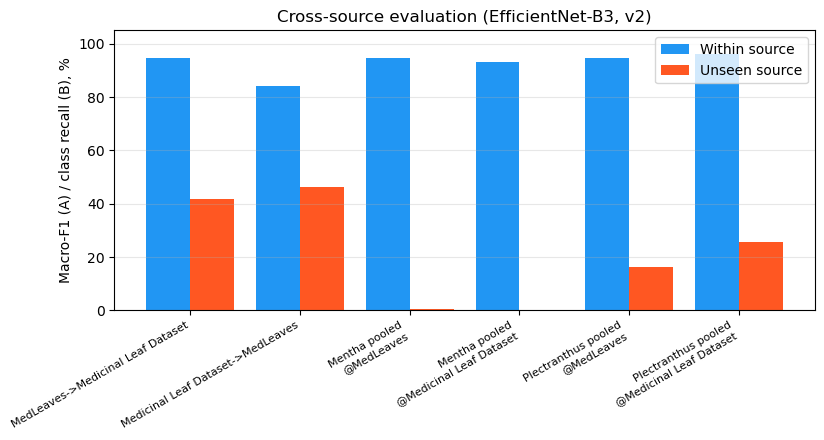


v1 vs v2:
experiment                                      setting   metric  v1_within  v1_cross  v2_within  v2_cross  cross_gain
         A          MedLeaves -> Medicinal Leaf Dataset macro-F1      85.61     36.25      94.74     41.80        5.55
         A          Medicinal Leaf Dataset -> MedLeaves macro-F1      73.68     45.11      84.21     46.16        1.05
         B                    Mentha_pooled @ MedLeaves   recall     100.00      0.00      94.74      0.51        0.51
         B       Mentha_pooled @ Medicinal Leaf Dataset   recall     100.00      0.00      93.10      0.00        0.00
         B              Plectranthus_pooled @ MedLeaves   recall     100.00     10.44      94.74     16.48        6.04
         B Plectranthus_pooled @ Medicinal Leaf Dataset   recall     100.00     12.10      96.30     25.81       13.71

All outputs in /home/ali/Desktop/Algerian_Lamiaceae_v3/results/cross_source_v2


In [8]:
def verdict(m):
    return ("small (<5 pts)" if m < 5 else "moderate (5-15 pts)" if m < 15 else "large (>15 pts)")
print("=" * 78 + "\nCROSS-SOURCE SUMMARY\n" + "=" * 78)
if len(pairwise_df):
    print(pairwise_df[["train_source", "test_source", "n_classes", "within_macro_f1", "within_F1_CI",
                       "cross_macro_f1", "cross_F1_CI", "F1_drop", "chance_acc"]].to_string(index=False))
    print(f"Experiment A: mean macro-F1 drop {pairwise_df.F1_drop.mean():.1f} pts -> {verdict(pairwise_df.F1_drop.mean())}\n")
good = loso_df[loso_df.sanity_ok] if len(loso_df) else loso_df
if len(loso_df):
    print(loso_df[["cls", "heldout_source", "n_heldout", "overall_bal_acc", "in_source_recall", "in_source_CI",
                   "unseen_source_recall", "unseen_CI", "recall_drop", "main_confusions"]].to_string(index=False))
    if (~loso_df.sanity_ok).any(): print(f"  WARNING: {(~loso_df.sanity_ok).sum()} run(s) below {MIN_SANITY_BAL_ACC:.0f}% balanced accuracy -- excluded")
    if len(good): print(f"Experiment B: mean recall drop {good.recall_drop.mean():.1f} pts -> {verdict(good.recall_drop.mean())}")

labs  = [f"{r.train_source}->{r.test_source}" for r in pairwise_df.itertuples()] + [f"{r.cls.replace('_', ' ')}\n@{r.heldout_source}" for r in good.itertuples()]
w_in  = list(pairwise_df.get("within_macro_f1", [])) + list(good.get("in_source_recall", []))
w_x   = list(pairwise_df.get("cross_macro_f1", [])) + list(good.get("unseen_source_recall", []))
if labs:
    x = np.arange(len(labs)); fig, ax = plt.subplots(figsize=(max(6, 1.4 * len(labs)), 4.5))
    ax.bar(x - 0.2, w_in, 0.4, label="Within source", color="#2196F3"); ax.bar(x + 0.2, w_x, 0.4, label="Unseen source", color="#FF5722")
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=30, ha="right", fontsize=8); ax.set_ylim(0, 105)
    ax.set_ylabel("Macro-F1 (A) / class recall (B), %"); ax.set_title("Cross-source evaluation (EfficientNet-B3, v2)")
    ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout()
    for ext in ("png", "pdf"): plt.savefig(os.path.join(OUTPUT_DIR, f"fig_cross_source.{ext}"), dpi=150, bbox_inches="tight")
    plt.show()

# v1 vs v2 (response letter)
rows = []
pA1, pB1 = os.path.join(V1_DIR, "cross_source_pairwise.csv"), os.path.join(V1_DIR, "cross_source_heldout_class_source.csv")
if os.path.exists(pA1) and len(pairwise_df):
    a1 = pd.read_csv(pA1).set_index(["train_source", "test_source"])
    rows += [{"experiment": "A", "setting": f"{r.train_source} -> {r.test_source}", "metric": "macro-F1",
              "v1_within": a1.loc[(r.train_source, r.test_source)].within_macro_f1, "v1_cross": a1.loc[(r.train_source, r.test_source)].cross_macro_f1,
              "v2_within": r.within_macro_f1, "v2_cross": r.cross_macro_f1} for r in pairwise_df.itertuples() if (r.train_source, r.test_source) in a1.index]
if os.path.exists(pB1) and len(loso_df):
    b1 = pd.read_csv(pB1).set_index(["cls", "heldout_source"])
    rows += [{"experiment": "B", "setting": f"{r.cls} @ {r.heldout_source}", "metric": "recall",
              "v1_within": b1.loc[(r.cls, r.heldout_source)].in_source_recall, "v1_cross": b1.loc[(r.cls, r.heldout_source)].unseen_source_recall,
              "v2_within": r.in_source_recall, "v2_cross": r.unseen_source_recall} for r in loso_df.itertuples() if (r.cls, r.heldout_source) in b1.index]
cmp_df = pd.DataFrame(rows)
if len(cmp_df):
    cmp_df["cross_gain"] = (cmp_df.v2_cross - cmp_df.v1_cross).round(2)
    print("\nv1 vs v2:\n" + cmp_df.to_string(index=False)); cmp_df.to_csv(os.path.join(OUTPUT_DIR, "v1_vs_v2_comparison.csv"), index=False)

json.dump({"config": CONFIG, "pairwise": pair_rows, "heldout_class_source": loso_rows,
           "probe": probe_df.to_dict("records")}, open(os.path.join(OUTPUT_DIR, "cross_source_results_v2.json"), "w"),
          indent=2, default=float)
print(f"\nAll outputs in {OUTPUT_DIR}")